In [1]:
!pip install xgboost lightgbm catboost
import numpy as np
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import LinearSVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 48.6 MB/s  0:00:02


/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


# **Read** **Data**

In [2]:
df = pd.read_csv("/content/egypt_House_prices(Target column Price).csv")

In [3]:
df

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3,3,400,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3,3,160,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3,2,165,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3,2,230,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2,3,160,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa
...,...,...,...,...,...,...,...,...,...,...,...,...
27356,Town House,890000,3,2,240,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,North Coast
27357,Town House,4000000,4,3,218,Unknown,Unknown,Unknown,Cash or Installment,Unknown,Finished,New Cairo - El Tagamoa
27358,Twin House,13800000,3,4,308,No,Unknown,Cairo Festival City,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa
27359,Stand Alone Villa,35000000,4,4,478,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Finished,Mokattam


# **EDA**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27361 entries, 0 to 27360
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Type            27179 non-null  object
 1   Price           27302 non-null  object
 2   Bedrooms        26938 non-null  object
 3   Bathrooms       26988 non-null  object
 4   Area            26824 non-null  object
 5   Furnished       27267 non-null  object
 6   Level           27284 non-null  object
 7   Compound        27219 non-null  object
 8   Payment_Option  27115 non-null  object
 9   Delivery_Date   27258 non-null  object
 10  Delivery_Term   27286 non-null  object
 11  City            27334 non-null  object
dtypes: object(12)
memory usage: 2.5+ MB


In [5]:
df.describe()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
count,27179,27302,26938,26988,26824,27267,27284,27219,27115,27258,27286,27334
unique,11,4180,12,12,785,3,14,559,4,10,5,183
top,Apartment,3000000,3,2,120,No,Unknown,Unknown,Cash or Installment,Ready to move,Finished,New Cairo - El Tagamoa
freq,8341,311,11677,9098,661,16447,10387,11013,10752,12094,14352,6771


In [6]:
df.isnull().sum()

,0
Type,182
Price,59
Bedrooms,423
Bathrooms,373
Area,537
Furnished,94
Level,77
Compound,142
Payment_Option,246
Delivery_Date,103


In [7]:
for i in df.columns:
  print(i , df[i].unique())
  print('*' * 50)

Type ['Duplex' 'Apartment' 'Penthouse' 'Studio' 'Unknown' nan 'Chalet'
 'Standalone Villa' 'Twin house' 'Town House' 'Stand Alone Villa'
 'Twin House']
**************************************************
Price ['4000000' '2250000' '1900000' ... '6276000' '11950000' '12284000']
**************************************************
Bedrooms ['3' '2' '4' '5' '1' 'Unknown' nan '7' '6' '10+' '8' '10' '9']
**************************************************
Bathrooms ['3' '2' '5' '1' '4' 'Unknown' nan '7' '10+' '6' '8' '10' '9']
**************************************************
Area ['400' '160' '165' '230' '222' '290' '144' '200' '146' '153' '94' '140'
 '130' '167' '229' '71' '220' '184' '178' '108' '136' '168' '190' '127'
 '155' '164' '121' '145' '163' '246' '170' '238' '90' '169' '175' '75'
 '282' '85' '100' '134' '158' '154.5' '380' '150' '128' '224' '135' '166'
 '143' '179' '183' '105' '189' '210' '106' '59' '123' '212' '110' '120'
 '195' '185' '124' '55' '182' '263' '198' '162' '301' '253'

In [8]:
df[df['Price']=='Unknown']

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
216,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
1186,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
2793,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
3655,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
3830,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
4236,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
4407,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
4468,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
5792,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale
5875,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown,Unknown Payment,Unknown,Unknown,Only in Apartments & Duplex for Sale


In [9]:
df.duplicated().sum()

np.int64(1909)

# **Cleaning**

In [10]:
# Normalize whitespace in text columns before duplicate removal.
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].map(lambda x: re.sub(r"\s+", " ", x.strip()) if isinstance(x, str) else x)

# Standardize confirmed property-type spelling variants.
df['Type'] = df['Type'].replace({
    'Twin house': 'Twin House',
    'Standalone Villa': 'Stand Alone Villa'
})

In [11]:
df.drop(df[df['Price'] == 'Unknown'].index, axis=0, inplace=True)

### City cleaning and standardization (before imputation and encoding)

This step removes missing City rows and non-location website labels, standardizes confirmed spelling variants, and keeps distinct areas separate. Do not impute City afterward.

In [12]:
df.replace('Unknown', np.nan, inplace=True)

# Clean City HERE, before categorical imputation, encoding, visualization and model training.
# Only confirmed spelling variants are merged; distinct districts/areas remain separate.
CITY_ALIAS_MAP = {
    'Mansura': 'Mansoura',
    'Mansuriyya': 'Al Mansuriyya',
    'Smoha': 'Smouha',
    'Glim': 'Gleem',
    'Zezenia': 'Zizinia',
    'Bacchus': 'Bakos',
    'Sidi Beshr': 'Sidi Bishr',
    'Bahray - Anfoshy': 'Bahary - Anfushi',
    'Dhahria': 'Al Dhahriya',
    'Maryotaya': 'Meryouteya',
    'Marsa Matrouh': 'Marsa Matruh',
    'Ras al-Bar': 'Ras El Bar',
    'Shubra al-Khaimah': 'Shubra El Kheima',
    'Shebin al-Koum': 'Shebin El Kom',
    'Mahalla al-Kobra': 'El Mahalla El Kubra',
    'Sharm al-Sheikh': 'Sharm El Sheikh',
    'Qasr al-Nil': 'Qasr El Nil',
    'Dar al-Salaam': 'Dar El Salam',
    'Masr al-Kadema': 'Masr El Qadima',
    'Gesr Al Suez': 'Gesr El Suez',
    'Helmeyat El Zaytoun': 'Helmeyet El Zaitoun',
    'Al Ibrahimiyyah': 'Ibrahimia',
    'Al Hadrah': 'El Hadra',
    'Abasiya': 'Abbassia',
    'Khosous': 'El Khusus',
    'Qanater al-Khairia': 'El Qanater El Khairia',
    'Kafr al-Sheikh City': 'Kafr El Sheikh',
    'Zahraa Al Maadi': 'Zahraa El Maadi',
    'Hadayek al-Ahram': 'Hadayek El Ahram',
    'Hadayek al-Kobba': 'Hadayek El Kobba',
    'Al Manial': 'Manial',
    'Al Amiriyyah': 'Al Amiriya',
    'Manshiyya': 'El Mansheya',
    'Alamein': 'El Alamein',
    'Dabaa': 'El Dabaa',
    'Gomrok': 'El Gomrok',
    'Borg al-Arab': 'Borg El Arab',
    'Haram': 'El Haram',
}

INVALID_CITY_PATTERNS = [
    r'(?i)^Only in\b',
    r'(?i)^About EMPG$',
    r'(?i)^\(View phone number\)$',
]

# Normalize City values, apply aliases, and identify website text / non-location labels.
df['City'] = df['City'].map(lambda x: re.sub(r"\s+", " ", x.strip()) if isinstance(x, str) else x)
df['City'] = df['City'].replace(CITY_ALIAS_MAP)
invalid_city_mask = pd.Series(False, index=df.index)
for pattern in INVALID_CITY_PATTERNS:
    invalid_city_mask |= df['City'].astype('string').str.match(pattern, na=False)

missing_city_before = int(df['City'].isna().sum())
invalid_city_rows = int(invalid_city_mask.sum())
df = df.loc[~invalid_city_mask].copy()
df.dropna(subset=['City'], inplace=True)

# Remove duplicates AFTER City aliases are standardized, so spelling variants don't survive as duplicate records.
df.drop_duplicates(inplace=True)
print(f'Rows removed: {missing_city_before} with missing City + {invalid_city_rows} non-location values')
print('Unique valid City values after standardization:', df['City'].nunique())
print('Missing City values after cleaning:', df['City'].isna().sum())

Rows removed: 27 with missing City + 61 non-location values
Unique valid City values after standardization: 178
Missing City values after cleaning: 0


In [13]:
df.isnull().sum()

,0
Type,164
Price,42
Bedrooms,398
Bathrooms,350
Area,499
Furnished,7866
Level,9653
Compound,10464
Payment_Option,217
Delivery_Date,9251


In [14]:
cols = ['Type','Furnished','Compound','Payment_Option','Delivery_Date','Delivery_Term']
from sklearn.impute import SimpleImputer

# City is deliberately excluded: missing/invalid City rows were removed in the previous cleaning cell.
for i in cols:
  impute = SimpleImputer(strategy='most_frequent')
  df[[i]] = impute.fit_transform(df[[i]])

In [15]:
df['Area'] = pd.to_numeric(df['Area'], errors='coerce')

In [16]:
from sklearn.impute import SimpleImputer

df['Bedrooms'] = df['Bedrooms'].replace('10+', 10)
df['Bathrooms'] = df['Bathrooms'].replace('10+', 10)
df['Level'] = df['Level'].replace('Ground', 0)

ncols = ['Bedrooms', 'Bathrooms', 'Level','Area']
for col in ncols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

for i in ncols:
    impute = SimpleImputer(strategy='median')
    df[[i]] = impute.fit_transform(df[[i]])

In [17]:
df.dropna(inplace=True)

In [18]:
df['Price'] = pd.to_numeric(df['Price'])

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25329 entries, 0 to 27360
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Type            25329 non-null  object 
 1   Price           25329 non-null  int64  
 2   Bedrooms        25329 non-null  float64
 3   Bathrooms       25329 non-null  float64
 4   Area            25329 non-null  float64
 5   Furnished       25329 non-null  object 
 6   Level           25329 non-null  float64
 7   Compound        25329 non-null  object 
 8   Payment_Option  25329 non-null  object 
 9   Delivery_Date   25329 non-null  object 
 10  Delivery_Term   25329 non-null  object 
 11  City            25329 non-null  object 
dtypes: float64(4), int64(1), object(7)
memory usage: 2.5+ MB


# **Visualization**

In [20]:
fig = px.histogram(df, x='Price', nbins=50, title='Distribution of House Prices in Egypt', labels={'Price': 'Price (EGP)'})
fig.update_layout(bargap=0.1)
fig.show()

In [21]:
# تحديد المدن الـ 15 الأكثر تكراراً لتجنب ازدحام الرسم البياني
top_cities = df['City'].value_counts().nlargest(15).index
df_filtered = df[df['City'].isin(top_cities)]

# إنشاء المخطط الصندوقي بمقارنة الأسعار حسب المدينة
fig_box = px.box(
    df_filtered,
    x='City',
    y='Price',
    title='مقارنة أسعار العقارات في أشهر 15 مدينة في مصر',
    labels={'Price': 'السعر (EGP)', 'City': 'المدينة'},
    color='City'
)
fig_box.update_layout(xaxis={'categoryorder':'total descending'}, showlegend=False)
fig_box.show()

In [22]:
# رسم مخطط مبعثر (Scatter Plot) لتوضيح العلاقة بشكل مرئي
fig_scatter = px.scatter(
    df,
    x='Area',
    y='Price',
    title='العلاقة بين المساحة وسعر العقار في مصر',
    labels={'Area': 'المساحة (متر مربع)', 'Price': 'السعر (EGP)'},
    trendline='ols',
    trendline_color_override='red'
)
fig_scatter.show()

In [23]:
# حساب سعر المتر المربع لكل عقار
df['Price_per_Sqm'] = df['Price'] / df['Area']

# حساب متوسط سعر المتر المربع مجمعاً حسب المدينة
avg_price_per_sqm = df.groupby('City')['Price_per_Sqm'].mean().reset_index()

# ترتيب النتائج تنازلياً حسب متوسط السعر
avg_price_per_sqm_sorted = avg_price_per_sqm.sort_values(by='Price_per_Sqm', ascending=False)

display(avg_price_per_sqm_sorted.head(20))

,City,Price_per_Sqm
14,Al Mansuriyya,79096.045198
68,Giza District,78431.347348
70,Gouna,65094.566824
140,Sadat,62818.517237
84,Kafr Abdo,33760.806286
83,Kabbary,32005.707297
102,Marsa Matruh,28756.278660
112,Mokattam,27669.517319
145,San Stefano,25736.865428
118,New Cairo - El Tagamoa,24330.432407


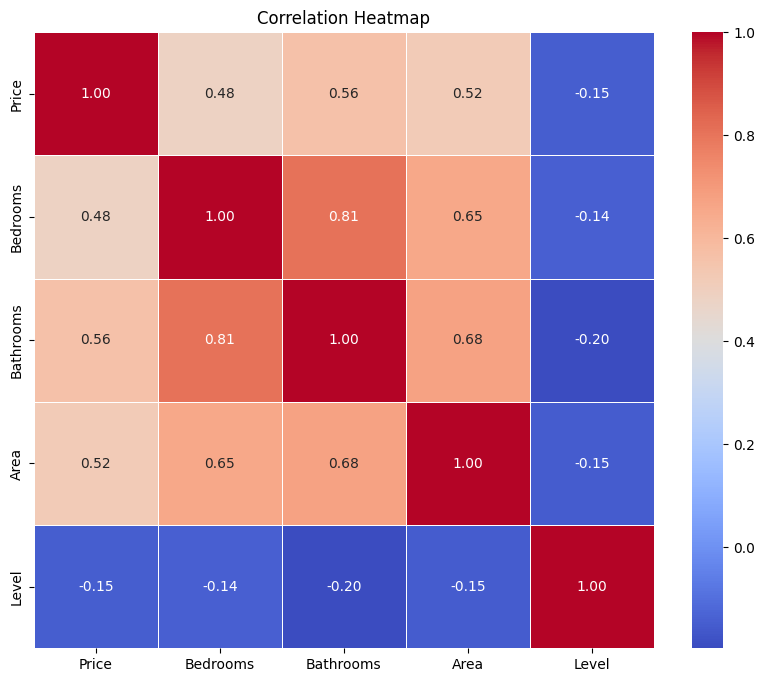

In [24]:
numeric_cols = df[['Price', 'Bedrooms', 'Bathrooms', 'Area', 'Level']]
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

In [25]:
df['Log_Price'] = np.log1p(df['Price'])
df['Log_Area'] = np.log1p(df['Area'])

print(f"Price (قبل): {df['Price'].skew():.2f}  ==>  Log_Price (بعد): {df['Log_Price'].skew():.2f}")
print(f"Area (قبل): {df['Area'].skew():.2f}  ==>  Log_Area (بعد): {df['Log_Area'].skew():.2f}")

fig_log = px.histogram(df, x='Log_Price', nbins=50, title='توزيع لوغاريتم السعر بعد تقليص القيم الشاذة')
fig_log.show()

Price (قبل): 6.81  ==>  Log_Price (بعد): -0.26
Area (قبل): 1.94  ==>  Log_Area (بعد): 0.36


In [26]:
lower_limit = df['Price'].quantile(0.01)
upper_limit = df['Price'].quantile(0.99)
df['Price_Capped'] = np.clip(df['Price'], lower_limit, upper_limit)

print(f"Price (قبل): {df['Price'].skew():.2f}  ==>  Price_Capped (بعد): {df['Price_Capped'].skew():.2f}")

fig_capped = px.histogram(df, x='Price_Capped', nbins=50, title='توزيع أسعار العقارات بعد تطبيق الـ Capping')
fig_capped.show()

Price (قبل): 6.81  ==>  Price_Capped (بعد): 2.36


# **Encoding**

In [27]:
ocols = ['Compound','City']
obcols = ['Type','Furnished','Payment_Option','Delivery_Date','Delivery_Term']

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

for i in ocols:
  df[i] = le.fit_transform(df[i])

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')

for i in obcols:
  ohe_encoded = ohe.fit_transform(df[[i]]).toarray()
  ohe_df = pd.DataFrame(ohe_encoded, columns=ohe.get_feature_names_out([i]),index=df.index)
  df = pd.concat([df, ohe_df],axis=1)
  df.drop(i,axis=1,inplace=True)

# **Preprocessing**

In [28]:
# EDITED: 'Price_per_Sqm' added to the drop list. It is Price / Area, i.e. it contains the answer (target leakage).
X = df.drop(['Price','Price_Capped','Log_Price','Price_per_Sqm'], axis=1)
y = df['Price']

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [30]:
print("X_train = ",X_train.shape ," y_train = ", y_train.shape)
print("X_test  = ",X_test.shape ," y_test  = ", y_test.shape)

X_train =  (20263, 34)  y_train =  (20263,)
X_test  =  (5066, 34)  y_test  =  (5066,)


In [31]:
ncols = ['Bedrooms', 'Bathrooms', 'Level','Area']
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train[ncols] = scaler.fit_transform(X_train[ncols])
X_test[ncols] = scaler.transform(X_test[ncols])

# **All Model Regression**

In [32]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski', p=1, n_jobs=-1), #  minkowski , euclidean , manhattan
    "SVM":LinearSVR(max_iter=5000, C=1, random_state=42), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10, n_jobs=-1), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [33]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



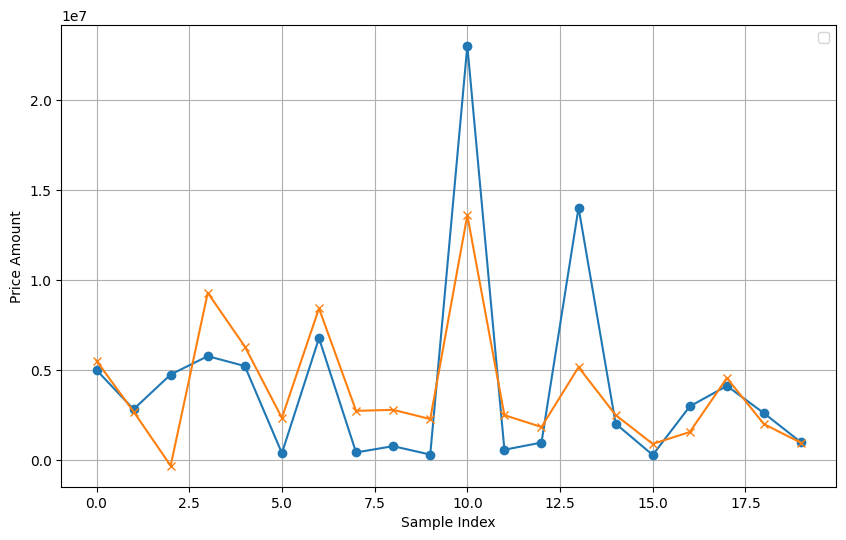

  7%|▋         | 1/15 [00:00<00:11,  1.18it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.117e+17, tolerance: 9.745e+13

/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



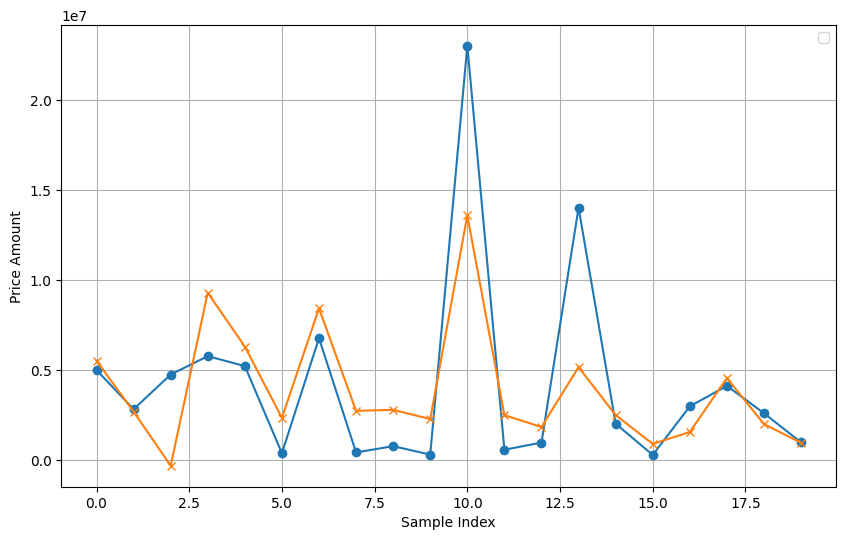

 13%|█▎        | 2/15 [00:13<01:42,  7.88s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



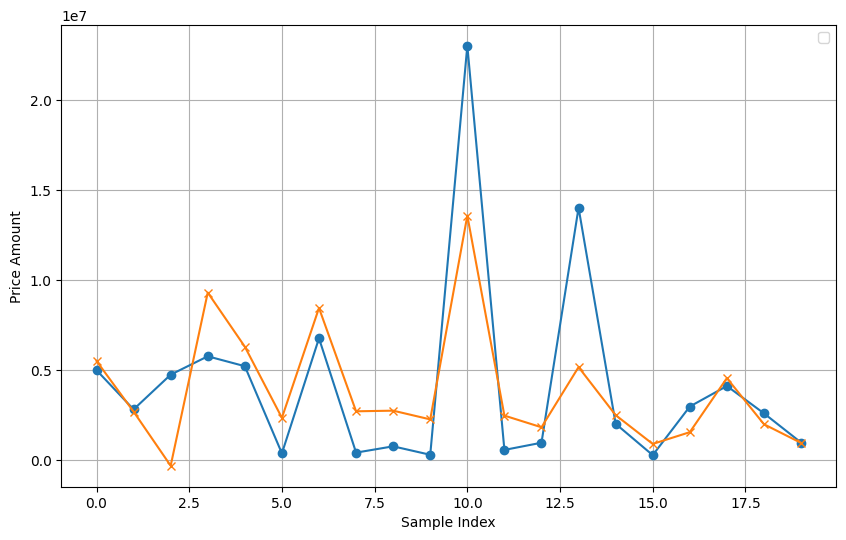

 20%|██        | 3/15 [00:14<00:55,  4.59s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



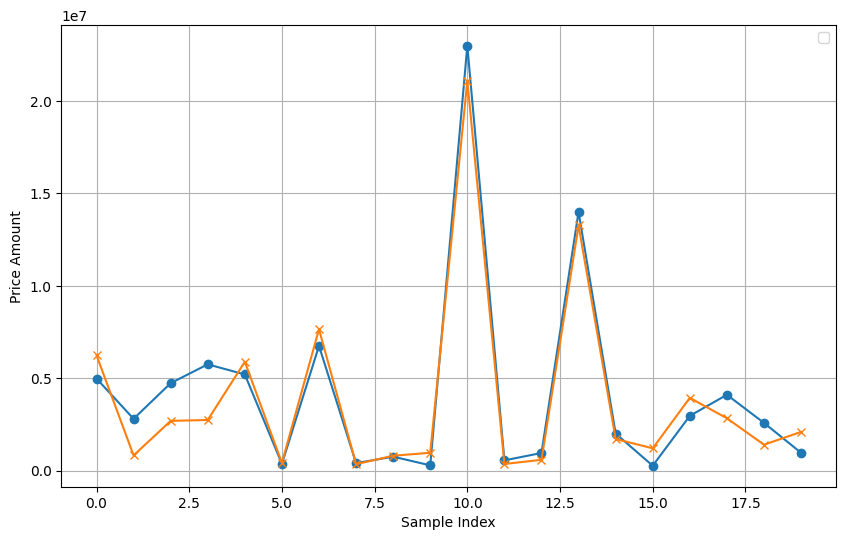

 27%|██▋       | 4/15 [00:35<02:04, 11.27s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



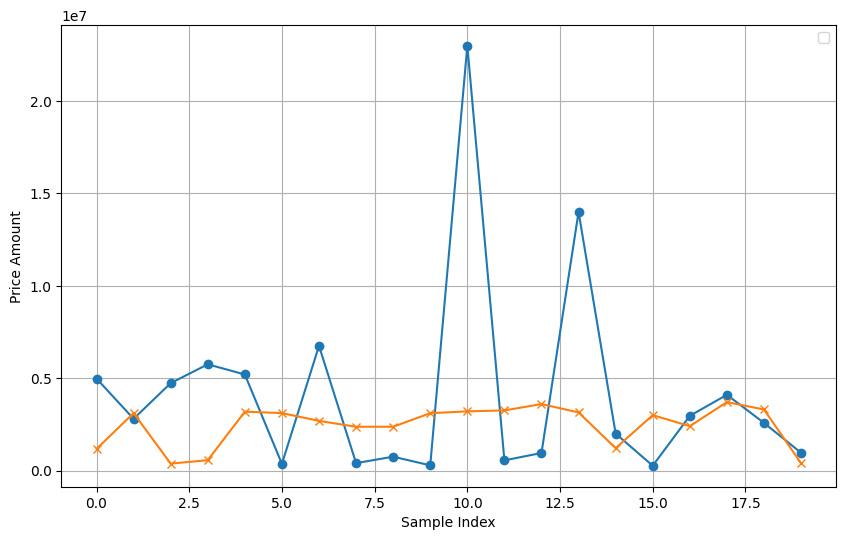

 33%|███▎      | 5/15 [00:36<01:12,  7.28s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



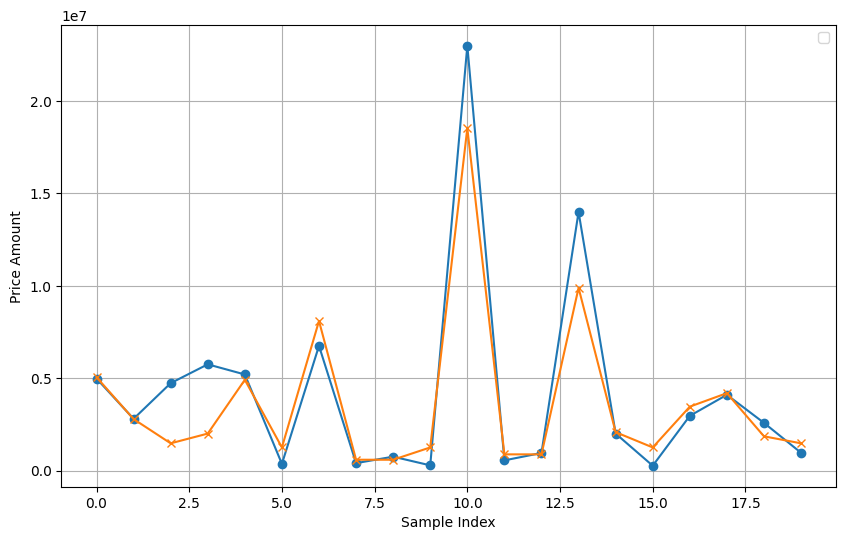

 40%|████      | 6/15 [00:36<00:43,  4.87s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



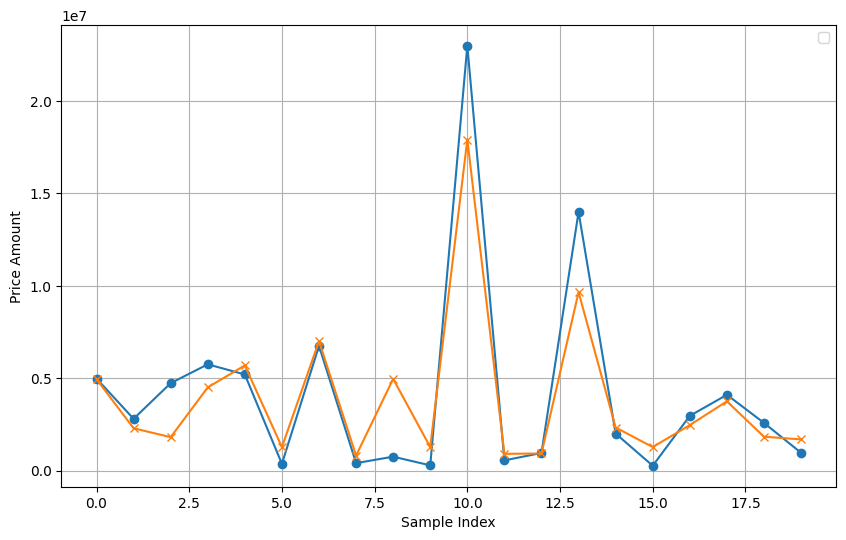

 47%|████▋     | 7/15 [00:38<00:31,  3.95s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



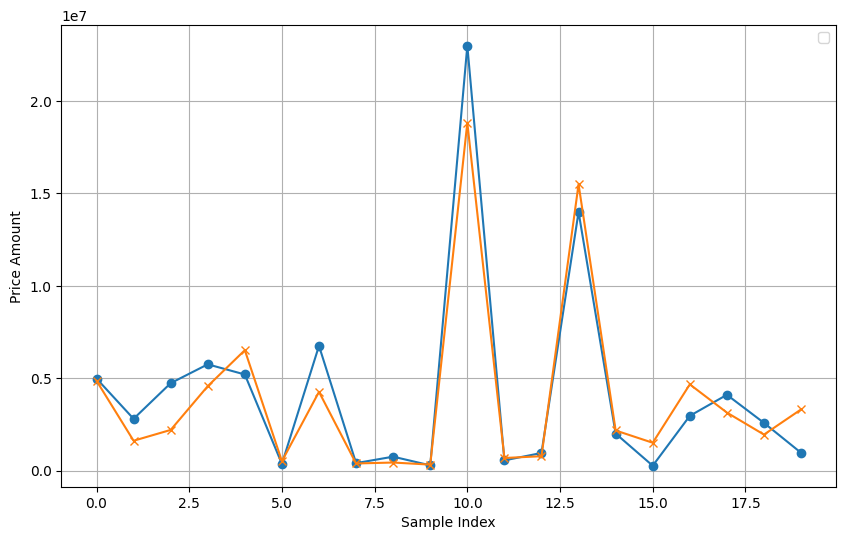

 53%|█████▎    | 8/15 [00:45<00:34,  4.99s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



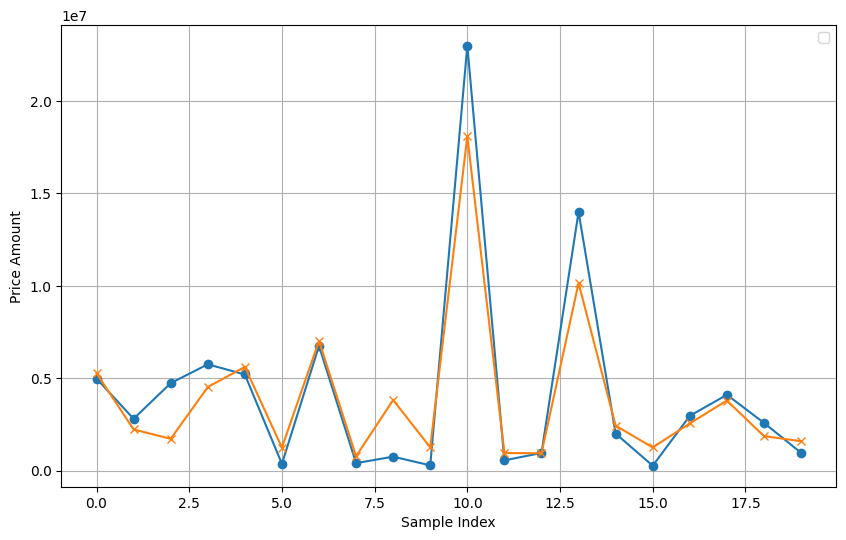

 60%|██████    | 9/15 [00:49<00:27,  4.57s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



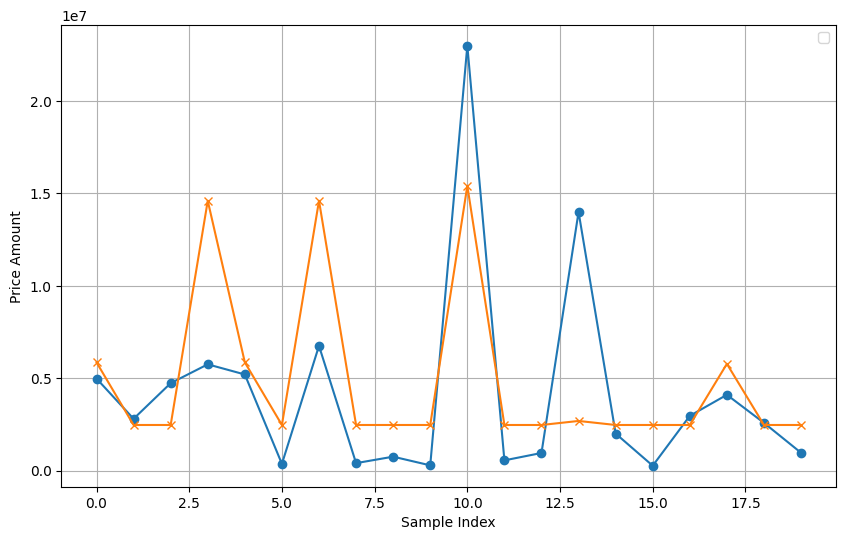

 67%|██████▋   | 10/15 [00:49<00:16,  3.34s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



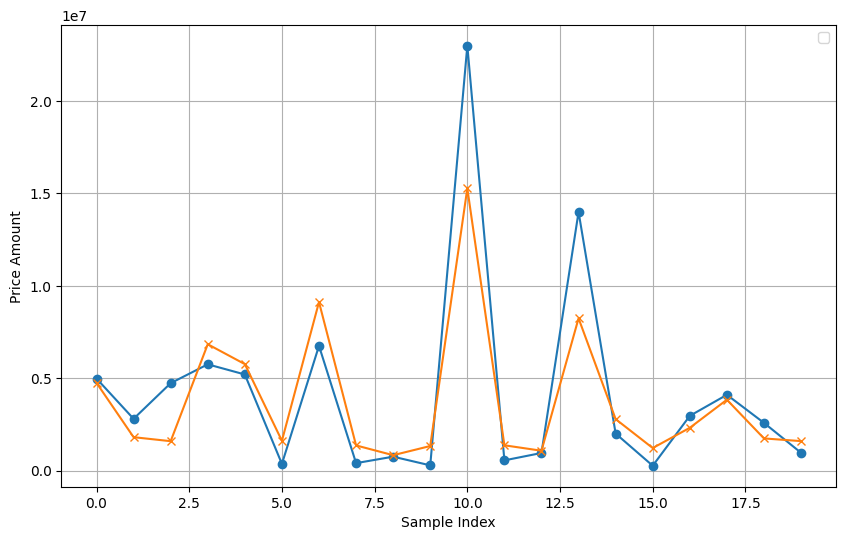

 73%|███████▎  | 11/15 [00:52<00:12,  3.06s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



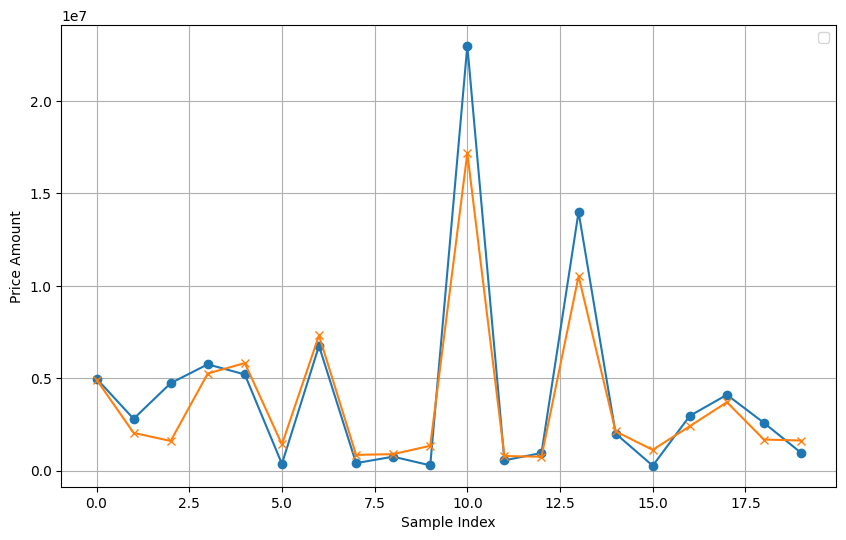

 80%|████████  | 12/15 [00:53<00:07,  2.44s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



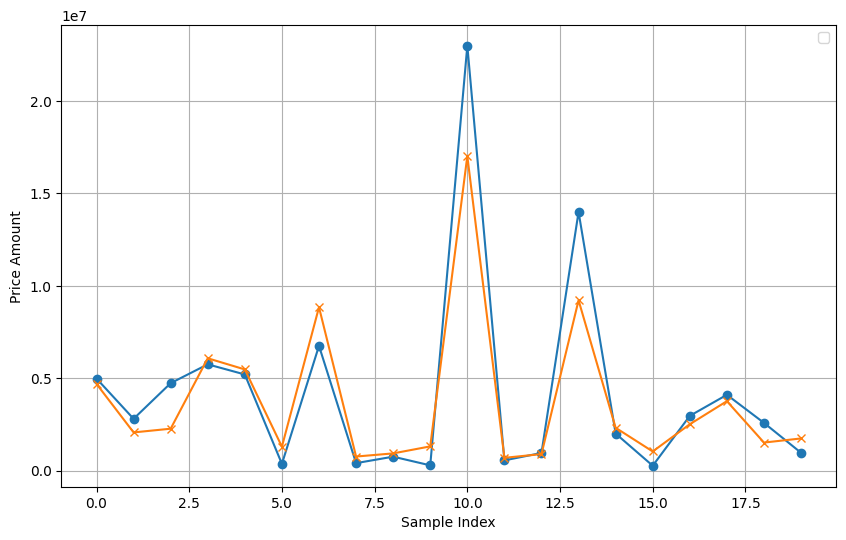

 87%|████████▋ | 13/15 [00:54<00:03,  1.96s/it]/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



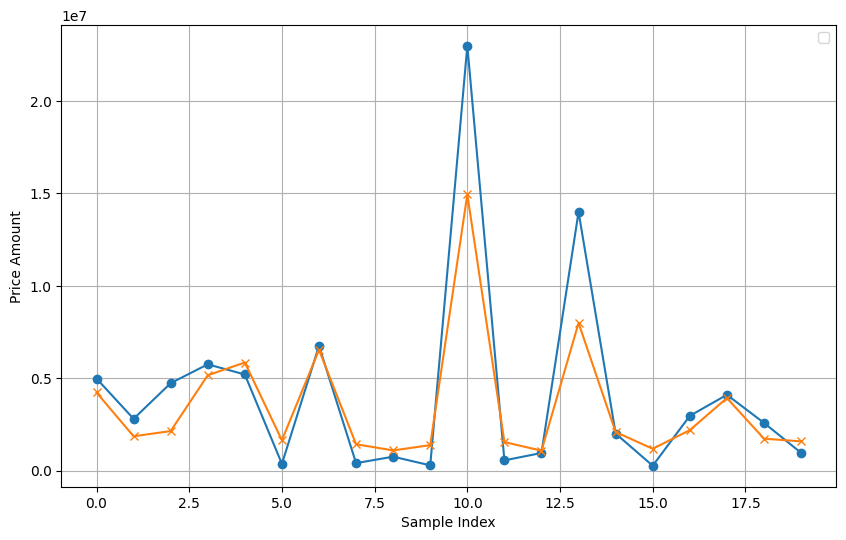

 93%|█████████▎| 14/15 [00:54<00:01,  1.56s/it]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003613 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 938
[LightGBM] [Info] Number of data points in the train set: 20263, number of used features: 33
[LightGBM] [Info] Start training from score 4831983.497113


/tmp/ipykernel_4337/3994069636.py:27: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



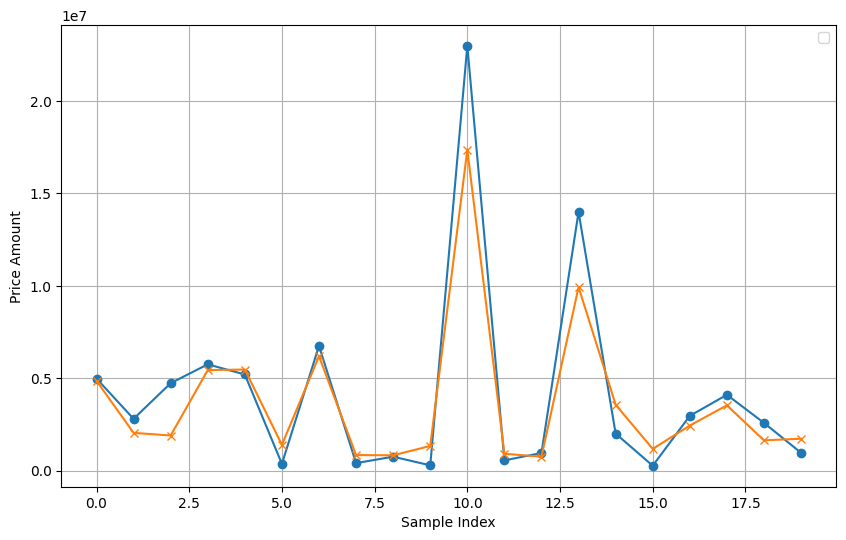

100%|██████████| 15/15 [00:55<00:00,  3.68s/it]


In [34]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, marker='o')
    plt.plot(range(20), y_pred_plot, marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Price Amount')
    plt.legend()
    plt.grid()
    plt.show()

# **Votting**

In [35]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


# **Stacking**

In [36]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [37]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [38]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
LightGBM,1.773313e+06,1.912754e+06,1.351509e+13,1.432224e+13,3.676287e+06,3.784473e+06,0.718972,0.673969
HistGradientBoosting,1.794801e+06,1.916529e+06,1.395935e+13,1.471057e+13,3.736221e+06,3.835436e+06,0.709735,0.665129
XGBoost,1.684656e+06,1.918302e+06,1.082130e+13,1.548027e+13,3.289574e+06,3.934498e+06,0.774986,0.647607
CatBoost,2.054197e+06,2.076397e+06,1.747290e+13,1.631413e+13,4.180060e+06,4.039075e+06,0.636675,0.628625
Random Forest,1.715637e+06,2.002207e+06,9.893142e+12,1.646866e+13,3.145337e+06,4.058160e+06,0.794286,0.625107
Bagging,1.724630e+06,2.005507e+06,9.973994e+12,1.657503e+13,3.158163e+06,4.071245e+06,0.792605,0.622686
KNN,1.523354e+06,1.860801e+06,1.449705e+13,1.692206e+13,3.807499e+06,4.113644e+06,0.698554,0.614786
GradientBoosting,2.113199e+06,2.102632e+06,1.993883e+13,1.757276e+13,4.465292e+06,4.191988e+06,0.585399,0.599974
Voting,1.105557e+06,1.912754e+06,5.625094e+12,1.432224e+13,2.371728e+06,3.784473e+06,0.883034,0.559715
Simple Voting,1.105557e+06,1.912754e+06,5.625094e+12,1.432224e+13,2.371728e+06,3.784473e+06,0.883034,0.559715


<Axes: >

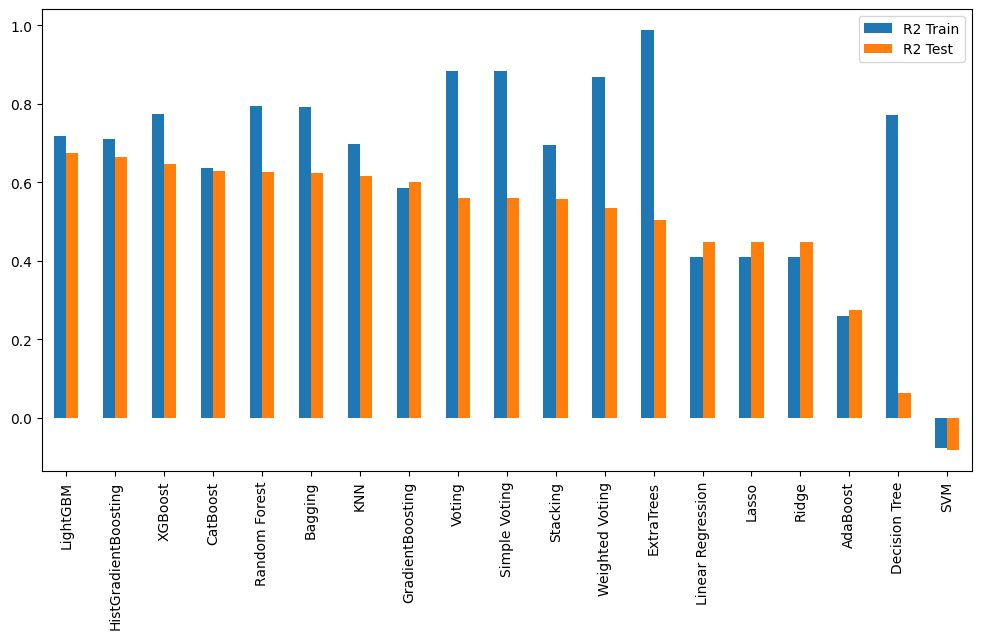

In [39]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

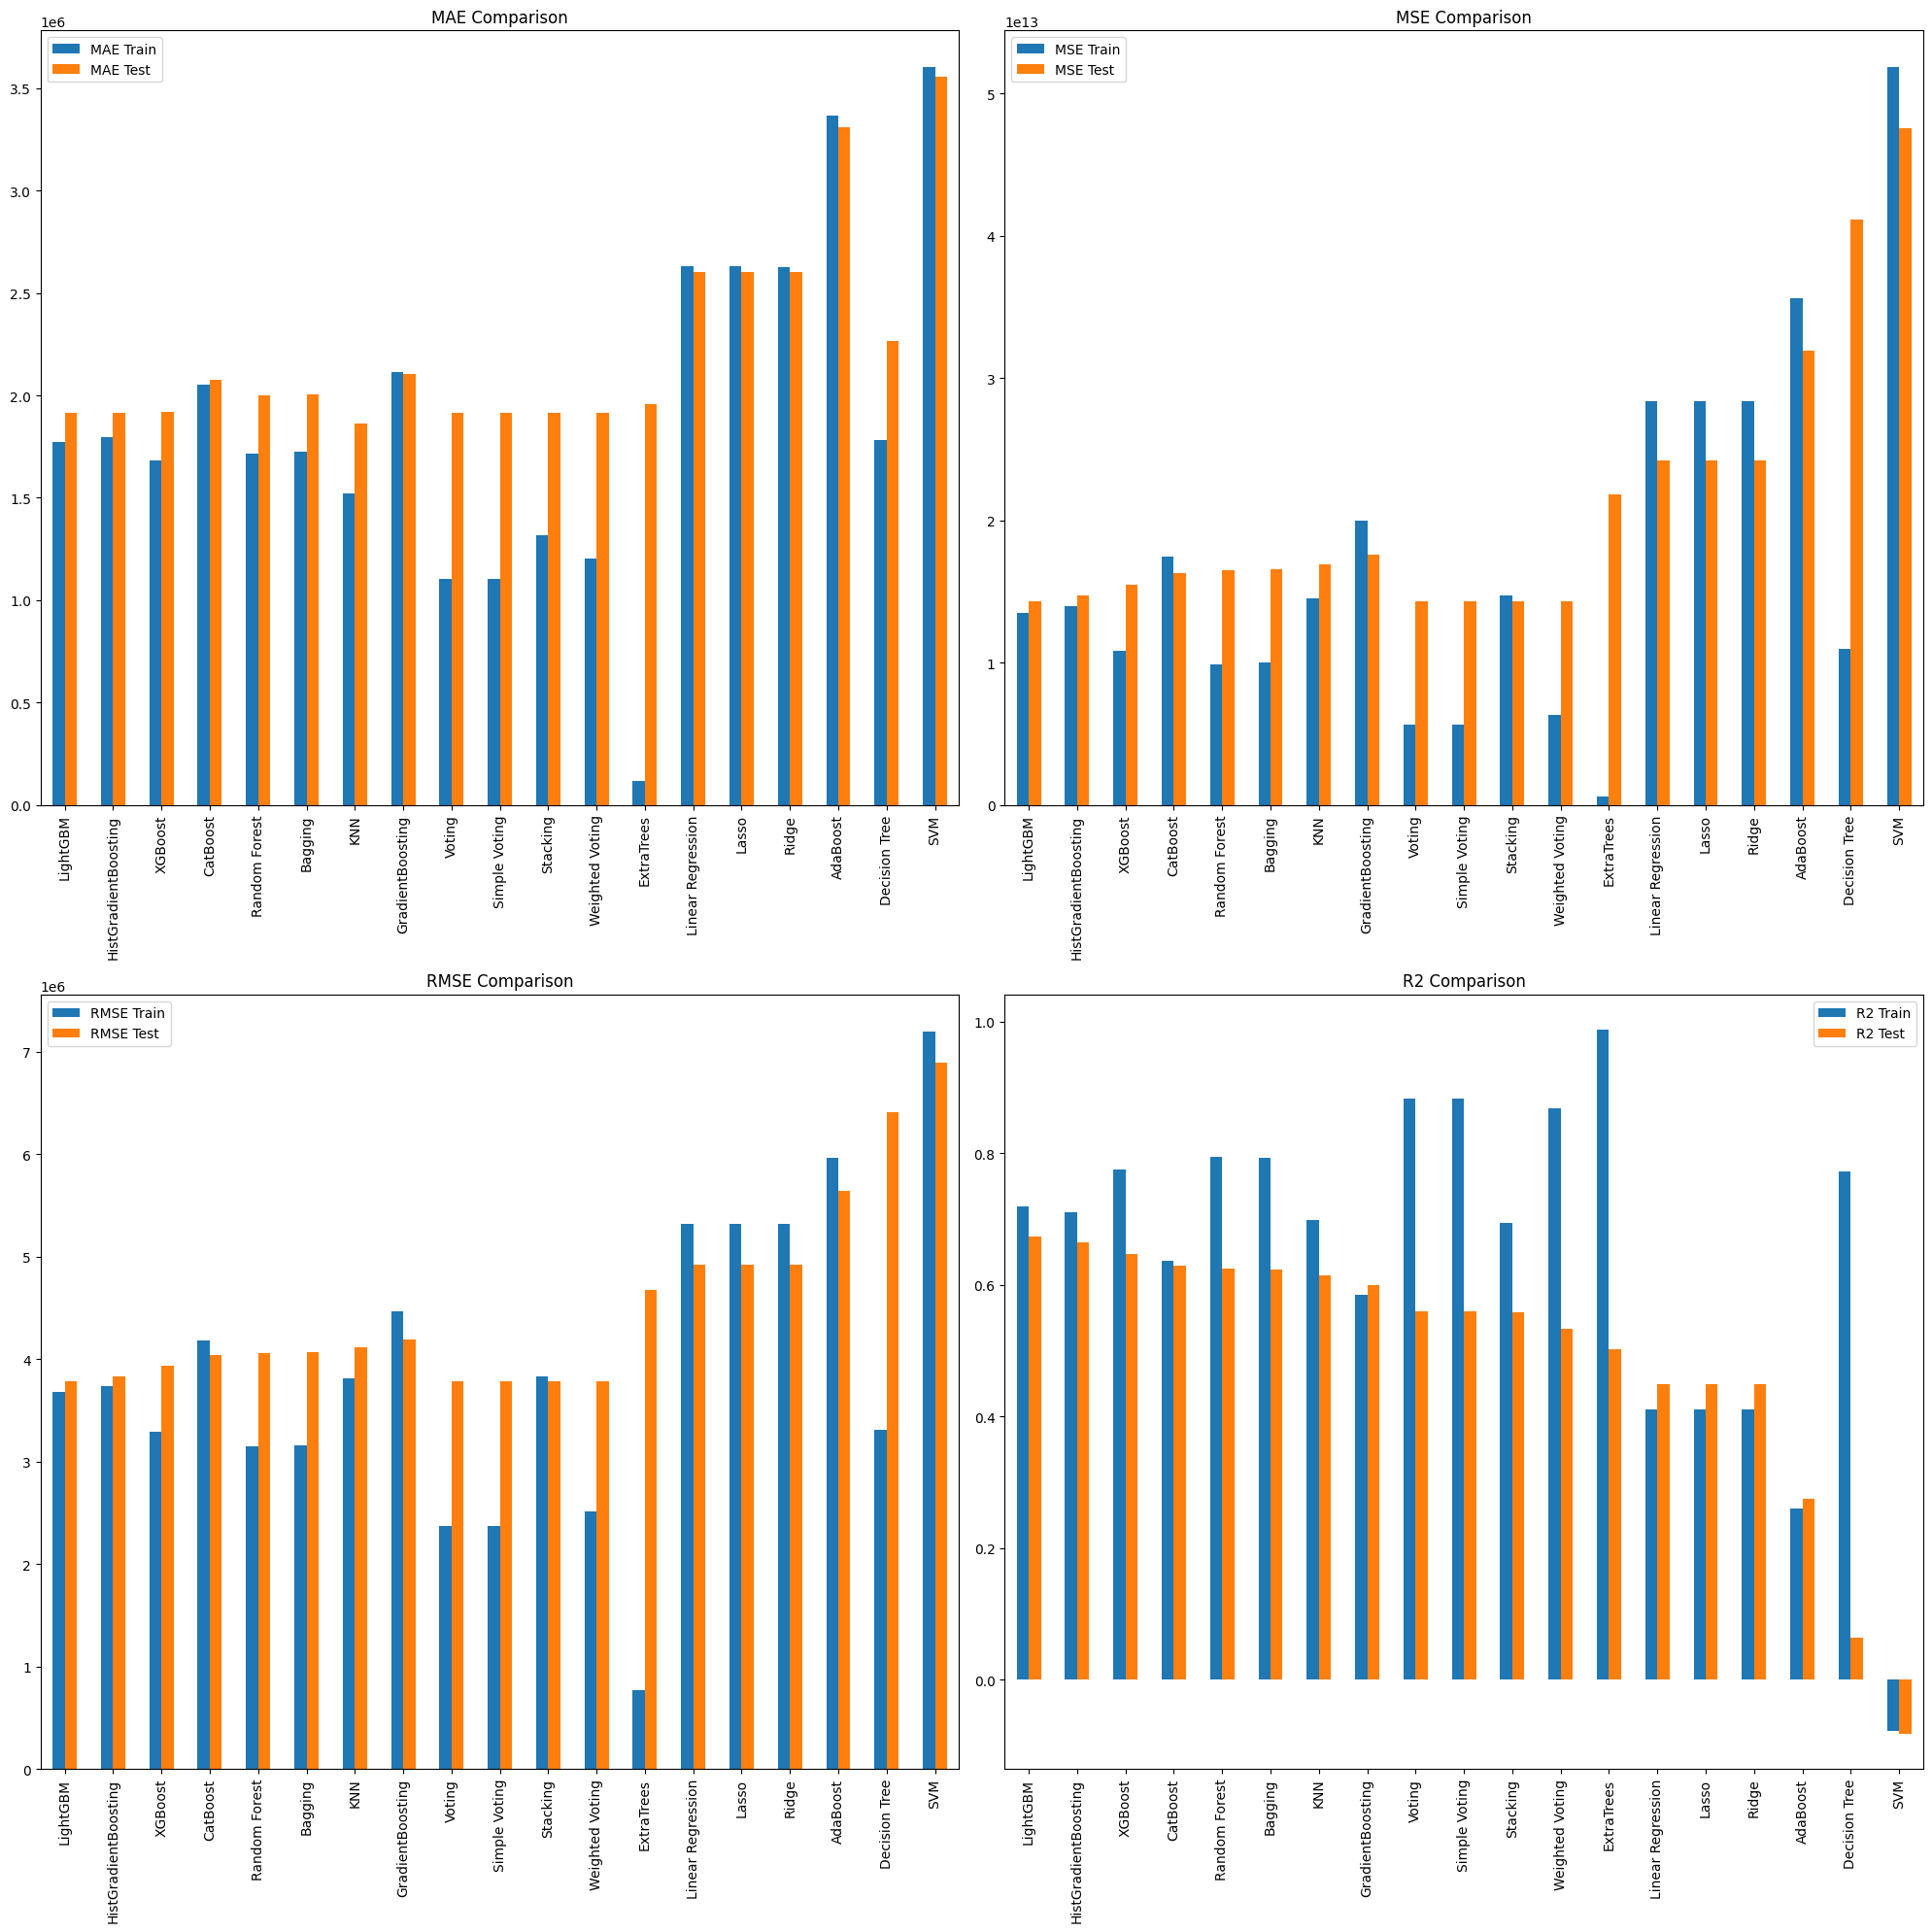

In [40]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()

# Corrected Deployment Section — Gradio + Streamlit

**Important:** The original EDA and modeling workflow remains at the top. City cleaning is applied in the original Cleaning section (immediately after replacing Unknown values), before imputation, encoding, visualization and model training. This lower section provides the separate deployment pipeline for Gradio and Streamlit. This section replaces the previous appended implementation (old cells 56–76).

The deployment flow uses:
- One cleaned dataset and one explicit City-cleaning policy.
- One train/test split.
- Preprocessing fitted only on training data (prevents leakage).
- One saved sklearn Pipeline shared by Gradio and Streamlit.
- Real category names in dropdowns; numeric fields stay numeric.

The original EDA and model-comparison cells are preserved for reference. Their old displayed metrics must not automatically be treated as the final deployment metrics: this section performs a fresh, leakage-safe evaluation.

## Step 1 — Install the required libraries

Run this cell once in each fresh Google Colab session.

In [41]:
!pip -q install gradio streamlit xgboost

## Step 2 — Load the CSV and audit the City column

Make sure the CSV is uploaded to the Colab session and its path matches `CSV_PATH`.

This cell displays the actual City values and their frequencies before cleaning.

In [42]:
from pathlib import Path
import re, json, joblib, warnings
import numpy as np
import pandas as pd

CSV_PATH = "/content/egypt_House_prices(Target column Price).csv"
ARTIFACT_DIR = Path("/content/house_price_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(CSV_PATH)
print("Raw shape:", raw.shape)
print("\\nDuplicate rows:", raw.duplicated().sum())
print("\\nMissing values:")
display(raw.isna().sum().to_frame("missing_count"))

print("\\nAll original City values and frequencies:")
display(raw["City"].value_counts(dropna=False).rename_axis("City").reset_index(name="count"))

Raw shape: (27361, 12)
\nDuplicate rows: 1909
\nMissing values:


,missing_count
Type,182
Price,59
Bedrooms,423
Bathrooms,373
Area,537
Furnished,94
Level,77
Compound,142
Payment_Option,246
Delivery_Date,103


\nAll original City values and frequencies:


,City,count
0,New Cairo - El Tagamoa,6771
1,North Coast,6362
2,Sheikh Zayed,2402
3,6th of October,1758
4,Ain Sukhna,1710
...,...,...
179,Aga,1
180,Qanater al-Khairia,1
181,Bella,1
182,Kafr Shukr,1


## Step 3 — Verified City cleaning policy

This version applies the decisions directly to the dataset:
- Remove rows where City is null.
- Remove rows where City contains website UI text / category labels rather than a location (for example `Only in Villas For Sale`, `About EMPG`, and `(View phone number)`).
- Normalize verified spelling variants to one canonical label.
- Keep Egyptian cities, districts, neighborhoods, resorts, and real-estate areas. `North Coast` is a region rather than a municipality, but it is a meaningful Egyptian real-estate location and is retained.
- `Faisal District` is standardized to `Faisal`. `Mansoura` and `Al Mansuriyya` remain separate; `Heliopolis` and `New Heliopolis`, `6th of October` and `Hadayek 6th of October`, and `New Damietta` and `Damietta City` also remain separate.

Geographic checks used public references for potentially questionable names and key aliases, including Egypt's CAPMAS, Cairo Governorate, World Bank / Egypt project material, Bayut Egypt, and mapped Alexandria localities. The detailed row-count audit is exported as `City_Values_Audit_Verified.csv`.

References used during review:
- Faisal / Faisal District: https://www.propertyfinder.eg/en/buy/giza/apartments-for-sale-hay-el-haram-faisal.html and https://www.egypttoday.com/Article/1/145733/Massive-Iftar-hosted-for-residents-of-22-streets-in-Faisal
- Al Dhahriya, Alexandria: https://mapcarta.com/N769119435 and https://www.eib.org/attachments/registers/166751224.pdf
- Port Said districts: https://documents1.worldbank.org/curated/en/380351499693943197/pdf/SFG1795-V9-EA-PUBLIC-Disclosed-7-10-2017.pdf
- Bella, Kafr El Sheikh: https://censusinfo.capmas.gov.eg/Metadata-en-v4.2/index.php/catalog/299/download/583
- Mansuriyya, Cairo: https://mapcarta.com/W711968070
- Sharabeya, Cairo: https://cairo.gov.eg/en/Pages/article.aspx?ArtID=416


In [43]:
# Verified aliases: only spelling variants / confirmed same-market-area labels are merged.
CITY_ALIAS_MAP = {
    "Mansura": "Mansoura",
    "Mansuriyya": "Al Mansuriyya",
    "Smoha": "Smouha",
    "Glim": "Gleem",
    "Zezenia": "Zizinia",
    "Bacchus": "Bakos",
    "Sidi Beshr": "Sidi Bishr",
    "Bahray - Anfoshy": "Bahary - Anfushi",
    "Dhahria": "Al Dhahriya",
    "Maryotaya": "Meryouteya",
    "Marsa Matrouh": "Marsa Matruh",
    "Ras al-Bar": "Ras El Bar",
    "Shubra al-Khaimah": "Shubra El Kheima",
    "Shebin al-Koum": "Shebin El Kom",
    "Mahalla al-Kobra": "El Mahalla El Kubra",
    "Sharm al-Sheikh": "Sharm El Sheikh",
    "Qasr al-Nil": "Qasr El Nil",
    "Dar al-Salaam": "Dar El Salam",
    "Masr al-Kadema": "Masr El Qadima",
    "Gesr Al Suez": "Gesr El Suez",
    "Helmeyat El Zaytoun": "Helmeyet El Zaitoun",
    "Al Ibrahimiyyah": "Ibrahimia",
    "Al Hadrah": "El Hadra",
    "Abasiya": "Abbassia",
    "Khosous": "El Khusus",
    "Qanater al-Khairia": "El Qanater El Khairia",
    "Kafr al-Sheikh City": "Kafr El Sheikh",
    "Zahraa Al Maadi": "Zahraa El Maadi",
    "Hadayek al-Ahram": "Hadayek El Ahram",
    "Hadayek al-Kobba": "Hadayek El Kobba",
    "Al Manial": "Manial",
    "Al Amiriyyah": "Al Amiriya",
    "Manshiyya": "El Mansheya",
    "Alamein": "El Alamein",
    "Dabaa": "El Dabaa",
    "Gomrok": "El Gomrok",
    "Borg al-Arab": "Borg El Arab",
    "Haram": "El Haram",
}

INVALID_CITY_PATTERNS = [
    r"(?i)^Only in\b",
    r"(?i)^About EMPG$",
    r"(?i)^\(View phone number\)$",
]

def normalize_text(value):
    if not isinstance(value, str):
        return value
    value = re.sub(r"\s+", " ", value.strip())
    return value if value else np.nan

def standardize_city(series):
    city = series.map(normalize_text).replace(CITY_ALIAS_MAP)
    invalid_mask = pd.Series(False, index=city.index)
    for pattern in INVALID_CITY_PATTERNS:
        invalid_mask |= city.astype("string").str.match(pattern, na=False)
    city = city.mask(invalid_mask, np.nan)
    return city, invalid_mask

city_clean_preview, invalid_city_mask = standardize_city(raw["City"])
city_audit = pd.DataFrame({
    "Original City": raw["City"].astype("string"),
    "Standardized City": city_clean_preview.astype("string"),
})
city_audit = (city_audit.groupby(["Original City", "Standardized City"], dropna=False)
              .size().reset_index(name="Rows"))
print("Rows with invalid UI/category text:", int(invalid_city_mask.sum()))
print("Rows with missing City:", int(raw["City"].isna().sum()))
print("Unique valid City values after alias normalization:", city_clean_preview.nunique(dropna=True))
print("\nInvalid values to be removed:")
display(city_audit[city_audit["Standardized City"].isna()].sort_values("Rows", ascending=False))
print("\nAliases applied:")
display(pd.DataFrame(list(CITY_ALIAS_MAP.items()), columns=["Original", "Canonical"]))


Rows with invalid UI/category text: 97
Rows with missing City: 27
Unique valid City values after alias normalization: 178

Invalid values to be removed:


,Original City,Standardized City,Rows
0,(View phone number),<NA>,61
183,<NA>,<NA>,27
130,Only in Villas For Sale,<NA>,15
128,Only in Apartments & Duplex for Sale,<NA>,14
5,About EMPG,<NA>,4
129,Only in Vacation Homes for Sale,<NA>,3



Aliases applied:


,Original,Canonical
0,Mansura,Mansoura
1,Mansuriyya,Al Mansuriyya
2,Smoha,Smouha
3,Glim,Gleem
4,Zezenia,Zizinia
5,Bacchus,Bakos
6,Sidi Beshr,Sidi Bishr
7,Bahray - Anfoshy,Bahary - Anfushi
8,Dhahria,Al Dhahriya
9,Maryotaya,Meryouteya


## Step 4 — Clean the dataset

The cleaning function now removes records with null / invalid City values before training. It applies the same canonical City aliases used by the audit. It does not impute City for a row that has no valid location. The exported cleaned CSV can be reused outside the notebook.


In [44]:
TARGET = "Price"
FEATURES = [
    "Type", "Bedrooms", "Bathrooms", "Area", "Furnished", "Level",
    "Compound", "Payment_Option", "Delivery_Date", "Delivery_Term", "City"
]
NUM_COLS = ["Bedrooms", "Bathrooms", "Area", "Level"]
LABEL_COLS = ["Compound", "City"]
OHE_COLS = ["Type", "Furnished", "Payment_Option", "Delivery_Date", "Delivery_Term"]
CAT_COLS = LABEL_COLS + OHE_COLS

def clean_data(raw_df):
    data = raw_df.copy()

    # Normalize spaces in all text columns before removing duplicates.
    for col in data.select_dtypes(include=["object"]).columns:
        data[col] = data[col].map(normalize_text)

    # Missing markers in categorical columns.
    for col in CAT_COLS:
        data[col] = data[col].map(
            lambda v: np.nan if isinstance(v, str) and v.startswith("Unknown") else v
        )

    # Standardize confirmed property-type spelling variants.
    data["Type"] = data["Type"].replace({
        "Twin house": "Twin House",
        "Standalone Villa": "Stand Alone Villa",
    })

    # Apply City aliases and remove non-location placeholders.
    data["City"], invalid_mask = standardize_city(data["City"])
    before_city_filter = len(data)
    data = data.dropna(subset=["City"])
    print("Rows removed because City was null / invalid:", before_city_filter - len(data))

    # Numeric cleanup.
    data["Bedrooms"] = data["Bedrooms"].replace("10+", 10)
    data["Bathrooms"] = data["Bathrooms"].replace("10+", 10)
    data["Level"] = data["Level"].replace({"Ground": 0})

    for col in NUM_COLS + [TARGET]:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    # A row without a target cannot be used for supervised training.
    data = data.dropna(subset=[TARGET])

    # Drop duplicates AFTER normalization.
    data = data.drop_duplicates().reset_index(drop=True)
    return data

df_model = clean_data(raw)
print("Rows after cleaning:", len(df_model))
print("Rows removed from raw:", len(raw) - len(df_model))
print("Remaining duplicate rows:", df_model.duplicated().sum())
print("Missing target values:", df_model[TARGET].isna().sum())
print("Valid City choices:", df_model["City"].nunique(dropna=True))
print("Missing City rows (must be 0):", df_model["City"].isna().sum())

# Save the cleaned dataset and the auditable city decision table.
CLEANED_CSV_PATH = "/content/egypt_house_prices_city_cleaned.csv"
CITY_AUDIT_PATH = "/content/City_Values_Audit_Verified.csv"
df_model.to_csv(CLEANED_CSV_PATH, index=False)
city_audit_export = pd.DataFrame({
    "Original City": raw["City"].astype("string"),
    "Standardized City": standardize_city(raw["City"])[0].astype("string"),
})
city_audit_export = (city_audit_export.groupby(["Original City", "Standardized City"], dropna=False)
                     .size().reset_index(name="Rows"))
city_audit_export["Action"] = np.where(city_audit_export["Standardized City"].isna(), "REMOVE", "KEEP")
city_audit_export["Reason"] = np.where(
    city_audit_export["Standardized City"].isna(),
    "Missing City or non-location website text",
    np.where(
        city_audit_export["Original City"].fillna("").isin(CITY_ALIAS_MAP),
        "Standardized verified spelling / alias",
        "Retained Egyptian location or real-estate area"
    )
)
city_audit_export.to_csv(CITY_AUDIT_PATH, index=False)
print("Saved:", CLEANED_CSV_PATH, "and", CITY_AUDIT_PATH)

print("\nFinal City values and frequencies:")
display(df_model["City"].value_counts(dropna=False).rename_axis("City").reset_index(name="count"))


Rows removed because City was null / invalid: 124
Rows after cleaning: 25328
Rows removed from raw: 2033
Remaining duplicate rows: 0
Missing target values: 0
Valid City choices: 178
Missing City rows (must be 0): 0
Saved: /content/egypt_house_prices_city_cleaned.csv and /content/City_Values_Audit_Verified.csv

Final City values and frequencies:


,City,count
0,New Cairo - El Tagamoa,6371
1,North Coast,5771
2,Sheikh Zayed,2161
3,6th of October,1650
4,Ain Sukhna,1563
...,...,...
173,Ataba,1
174,El Qanater El Khairia,1
175,Bella,1
176,Kafr Shukr,1


## Step 5 — Leakage-safe model comparison and final pipeline

All candidate models use the **same** training split and preprocessing. Imputers, scalers and encoders are fitted on training data only.

The primary selection metric is MAE (average absolute error in EGP); RMSE and R² are also reported. This is a fresh evaluation and may differ from the historical metrics in the earlier cells.

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from xgboost import XGBRegressor

X = df_model[FEATURES].copy()
y = df_model[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", MinMaxScaler()),
        ]), NUM_COLS),
        ("ordinal", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OrdinalEncoder(
                handle_unknown="use_encoded_value", unknown_value=-1
            )),
        ]), LABEL_COLS),
        ("onehot", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), OHE_COLS),
    ])

candidates = {
    "Random Forest": RandomForestRegressor(
        n_estimators=120, max_depth=18, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=120, max_depth=18, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150, learning_rate=0.08, max_leaf_nodes=31, random_state=42
    ),
    "XGBoost": XGBRegressor(
        n_estimators=150, learning_rate=0.05, max_depth=6,
        random_state=42, verbosity=0, n_jobs=-1
    ),
}

evaluation = {}
fitted_candidates = {}

for name, estimator in candidates.items():
    candidate_pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", estimator),
    ])
    candidate_pipeline.fit(X_train, y_train)
    predictions = candidate_pipeline.predict(X_test)
    evaluation[name] = {
        "MAE (EGP)": mean_absolute_error(y_test, predictions),
        "RMSE (EGP)": mean_squared_error(y_test, predictions) ** 0.5,
        "R2": r2_score(y_test, predictions),
    }
    fitted_candidates[name] = candidate_pipeline

evaluation_df = pd.DataFrame(evaluation).T.sort_values("MAE (EGP)")
display(evaluation_df.style.format({
    "MAE (EGP)": "{:,.0f}", "RMSE (EGP)": "{:,.0f}", "R2": "{:.4f}"
}))

# Select by the primary metric: lowest test MAE.
BEST_MODEL_NAME = evaluation_df.index[0]
final_pipeline = fitted_candidates[BEST_MODEL_NAME]
print("Selected model by lowest test MAE:", BEST_MODEL_NAME)

# Persist the exact fitted preprocessing + model pipeline.
joblib.dump(final_pipeline, ARTIFACT_DIR / "house_price_pipeline.joblib")

# Store only categories observed in the training data for dropdown menus.
categories = {}
for col in CAT_COLS:
    values = X_train[col].dropna().astype(str).unique().tolist()
    categories[col] = sorted(values, key=str.casefold)

defaults = {}
for col in CAT_COLS:
    mode = X_train[col].mode(dropna=True)
    defaults[col] = str(mode.iloc[0]) if not mode.empty else categories[col][0]

numeric_meta = {}
for col in NUM_COLS:
    numeric_meta[col] = {
        "min": float(np.floor(X_train[col].min())),
        "max": float(np.ceil(X_train[col].max())),
        "median": float(X_train[col].median()),
    }

test_predictions = final_pipeline.predict(X_test)
test_metrics = {
    "MAE": float(mean_absolute_error(y_test, test_predictions)),
    "RMSE": float(mean_squared_error(y_test, test_predictions) ** 0.5),
    "R2": float(r2_score(y_test, test_predictions)),
}

metadata = {
    "feature_order": FEATURES,
    "categories": categories,
    "defaults": defaults,
    "numeric": numeric_meta,
    "test_metrics": test_metrics,
    "model_name": BEST_MODEL_NAME,
    "n_train_rows": int(len(X_train)),
    "city_alias_map": CITY_ALIAS_MAP,
    "invalid_city_patterns": INVALID_CITY_PATTERNS,
}
(ARTIFACT_DIR / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Saved artifacts:", [p.name for p in ARTIFACT_DIR.iterdir()])

,MAE (EGP),RMSE (EGP),R2
Random Forest,"1,818,242","3,725,930",0.6479
Extra Trees,"1,920,318","3,906,862",0.6129
XGBoost,"1,921,608","3,699,390",0.6529
HistGradientBoosting,"1,921,818","3,624,045",0.6669


Selected model by lowest test MAE: Random Forest
Saved artifacts: ['house_price_pipeline.joblib', 'metadata.json']


## Step 6 — Create the shared prediction module

Both applications import this same module. It loads the fitted pipeline; it never refits an encoder or scaler.

In [46]:
%%writefile /content/predictor.py
import json, math, re
from functools import lru_cache
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

ARTIFACT_DIR = Path("/content/house_price_artifacts")
NOT_SPECIFIED = "Not specified"

FIELDS = {
    "Type":           {"kind": "category", "label": "Property type", "optional": False},
    "City":           {"kind": "category", "label": "City / area", "optional": False},
    "Compound":       {"kind": "category", "label": "Compound", "optional": True},
    "Area":           {"kind": "float",    "label": "Area (m²)", "optional": False},
    "Bedrooms":       {"kind": "int",      "label": "Bedrooms", "optional": False},
    "Bathrooms":      {"kind": "int",      "label": "Bathrooms", "optional": False},
    "Level":          {"kind": "int",      "label": "Floor number", "optional": False},
    "Furnished":      {"kind": "category", "label": "Furnished?", "optional": True},
    "Payment_Option": {"kind": "category", "label": "Payment option", "optional": True},
    "Delivery_Date":  {"kind": "category", "label": "Delivery date", "optional": True},
    "Delivery_Term":  {"kind": "category", "label": "Finishing level", "optional": True},
}

@lru_cache(maxsize=1)
def load_artifacts():
    model_path = ARTIFACT_DIR / "house_price_pipeline.joblib"
    meta_path = ARTIFACT_DIR / "metadata.json"
    if not model_path.exists() or not meta_path.exists():
        raise FileNotFoundError("Run the training/export cell first; model artifacts were not found.")
    model = joblib.load(model_path)
    metadata = json.loads(meta_path.read_text(encoding="utf-8"))
    return model, metadata

def get_metadata():
    return load_artifacts()[1]

def choices_for(col):
    choices = list(get_metadata()["categories"][col])
    if FIELDS[col]["optional"]:
        choices = [NOT_SPECIFIED] + choices
    return choices

def default_for(col):
    info = FIELDS[col]
    meta = get_metadata()
    if info["kind"] == "category":
        if col == "Compound":
            return NOT_SPECIFIED
        return meta["defaults"][col]
    median = meta["numeric"][col]["median"]
    return int(round(median)) if info["kind"] == "int" else float(median)

def number_limits(col):
    n = get_metadata()["numeric"][col]
    return n["min"], n["max"]

def validate(inputs):
    meta = get_metadata()
    errors = []
    for col in meta["feature_order"]:
        info, value = FIELDS[col], inputs.get(col)
        if info["kind"] == "category":
            if value is None or value == "":
                errors.append(f"Choose a value for {info['label']}.")
            elif value == NOT_SPECIFIED and not info["optional"]:
                errors.append(f"{info['label']} is required.")
            elif value != NOT_SPECIFIED and value not in meta["categories"][col]:
                errors.append(f"{value!r} is not a valid {info['label']} choice.")
        else:
            try:
                number = float(value)
            except (TypeError, ValueError):
                errors.append(f"{info['label']} must be numeric.")
                continue
            lo, hi = number_limits(col)
            if not math.isfinite(number):
                errors.append(f"{info['label']} must be a finite number.")
            elif info["kind"] == "int" and not number.is_integer():
                errors.append(f"{info['label']} must be a whole number.")
            elif not lo <= number <= hi:
                errors.append(f"{info['label']} must be between {lo:g} and {hi:g}.")
    return errors

def build_row(inputs):
    order = get_metadata()["feature_order"]
    row = {}
    for col in order:
        value = inputs[col]
        if FIELDS[col]["kind"] == "category":
            row[col] = np.nan if value == NOT_SPECIFIED else str(value)
        else:
            row[col] = int(value) if FIELDS[col]["kind"] == "int" else float(value)
    return pd.DataFrame([row], columns=order)

def predict_price(inputs):
    errors = validate(inputs)
    if errors:
        raise ValueError("\n".join(errors))
    model, _ = load_artifacts()
    prediction = float(model.predict(build_row(inputs))[0])
    return max(prediction, 0.0)

def format_price(price):
    return f"{price:,.0f} EGP"

def explanation():
    meta = get_metadata()
    m = meta["test_metrics"]
    return (
        f"Model: **{meta['model_name']}**. "
        f"On the held-out test set: MAE **{m['MAE']:,.0f} EGP**, "
        f"RMSE **{m['RMSE']:,.0f} EGP**, R² **{m['R2']:.3f}**. "
        "This is an estimate, not an official property valuation."
    )

Writing /content/predictor.py


## Step 7 — Create the Gradio application

In [47]:
%%writefile /content/gradio_app.py
import gradio as gr
import predictor as P

ORDER = list(P.FIELDS.keys())

def make_input(col):
    info = P.FIELDS[col]
    if info["kind"] == "category":
        return gr.Dropdown(
            choices=P.choices_for(col),
            value=P.default_for(col),
            label=info["label"],
            filterable=True,
            allow_custom_value=False,
        )
    lo, hi = P.number_limits(col)
    if info["kind"] == "int":
        return gr.Number(
            value=P.default_for(col), label=info["label"],
            minimum=lo, maximum=hi, precision=0, step=1,
        )
    return gr.Number(
        value=P.default_for(col), label=info["label"],
        minimum=lo, maximum=hi, precision=2, step=0.1,
    )

def predict(*values):
    inputs = dict(zip(ORDER, values))
    try:
        price = P.predict_price(inputs)
        return f"## Estimated price: {P.format_price(price)}\n\n{P.explanation()}"
    except Exception as exc:
        return f"### Please check your inputs\n{exc}"

def reset():
    return [P.default_for(c) for c in ORDER] + ["Enter the property details and press Predict."]

def build_demo():
    with gr.Blocks(title="Egypt House Price Predictor") as demo:
        gr.Markdown("# Egypt House Price Predictor\nEnter real property details to estimate the asking price.")
        components = {}
        with gr.Row():
            with gr.Column():
                gr.Markdown("### Location and property")
                for c in ["Type", "City", "Compound"]:
                    components[c] = make_input(c)
                gr.Markdown("### Size and layout")
                for c in ["Area", "Bedrooms", "Bathrooms", "Level"]:
                    components[c] = make_input(c)
            with gr.Column():
                gr.Markdown("### Sale details")
                for c in ["Furnished", "Payment_Option", "Delivery_Date", "Delivery_Term"]:
                    components[c] = make_input(c)
                with gr.Row():
                    predict_btn = gr.Button("Predict price", variant="primary")
                    reset_btn = gr.Button("Reset")
                result = gr.Markdown("Enter the property details and press Predict.")
        inputs = [components[c] for c in ORDER]
        predict_btn.click(predict, inputs=inputs, outputs=result)
        reset_btn.click(reset, inputs=None, outputs=inputs + [result])
    return demo

demo = build_demo()

if __name__ == "__main__":
    demo.launch(share=True)

Writing /content/gradio_app.py


## Step 8 — Create the Streamlit application

In [48]:
%%writefile /content/app.py
import streamlit as st
import predictor as P

st.set_page_config(page_title="Egypt House Price Predictor", page_icon="🏠", layout="wide")

st.title("🏠 Egypt House Price Predictor")
st.write("Enter the property details below to estimate its asking price.")

try:
    meta = P.get_metadata()
except Exception as exc:
    st.error(str(exc))
    st.stop()

with st.sidebar:
    st.header("About this model")
    st.write(f"Selected model: **{meta['model_name']}**")
    st.metric("Test MAE", f"{meta['test_metrics']['MAE']:,.0f} EGP")
    st.metric("Test R²", f"{meta['test_metrics']['R2']:.3f}")
    st.caption("The result is an estimate, not an official valuation.")

def make_input(col):
    info = P.FIELDS[col]
    if info["kind"] == "category":
        options = P.choices_for(col)
        default = P.default_for(col)
        return st.selectbox(
            info["label"], options,
            index=options.index(default),
            key=col,
            help="Choose a real category from the training data."
        )
    lo, hi = P.number_limits(col)
    if info["kind"] == "int":
        return st.number_input(
            info["label"], min_value=int(lo), max_value=int(hi),
            value=int(P.default_for(col)), step=1, key=col
        )
    return st.number_input(
        info["label"], min_value=float(lo), max_value=float(hi),
        value=float(P.default_for(col)), step=0.1, format="%.2f", key=col
    )

with st.form("property_form"):
    left, right = st.columns(2)
    values = {}
    with left:
        st.subheader("📍 Location and property")
        for col in ["Type", "City", "Compound"]:
            values[col] = make_input(col)
        st.subheader("📐 Size and layout")
        c1, c2 = st.columns(2)
        with c1:
            values["Area"] = make_input("Area")
            values["Bathrooms"] = make_input("Bathrooms")
        with c2:
            values["Bedrooms"] = make_input("Bedrooms")
            values["Level"] = make_input("Level")
    with right:
        st.subheader("📝 Sale details")
        for col in ["Furnished", "Payment_Option", "Delivery_Date", "Delivery_Term"]:
            values[col] = make_input(col)
    submitted = st.form_submit_button("Predict price", type="primary", use_container_width=True)

if submitted:
    try:
        price = P.predict_price(values)
        st.divider()
        st.subheader("Prediction")
        st.metric("Estimated price", P.format_price(price))
        st.info(P.explanation())
        with st.expander("Show submitted details"):
            st.json(values)
    except Exception as exc:
        st.error(str(exc))

Writing /content/app.py


## Step 9 — Test the shared prediction logic

The same `predictor.py` function is called by both interfaces. This test compares the saved pipeline prediction with the shared prediction function on a real held-out row.

In [49]:
import sys, importlib
sys.path.insert(0, "/content")
import predictor as P
import numpy as np
import pandas as pd
importlib.reload(P)

meta = P.get_metadata()
valid_rows = X_test.dropna(subset=NUM_COLS + ["Type", "City"])
selected = None
for _, candidate in valid_rows.iterrows():
    ok = True
    for col in CAT_COLS:
        if pd.notna(candidate[col]) and str(candidate[col]) not in meta["categories"][col]:
            ok = False
            break
    if ok:
        selected = candidate
        break
if selected is None:
    raise RuntimeError("Could not find a held-out row whose categories are all present in training.")

test_input = {}
for col in FEATURES:
    value = selected[col]
    if col in NUM_COLS:
        test_input[col] = int(round(float(value))) if col in ["Bedrooms", "Bathrooms", "Level"] else float(value)
    else:
        test_input[col] = P.NOT_SPECIFIED if pd.isna(value) and P.FIELDS[col]["optional"] else (
            meta["defaults"][col] if pd.isna(value) else str(value)
        )

direct_prediction = float(final_pipeline.predict(pd.DataFrame([selected.to_dict()], columns=FEATURES))[0])
shared_prediction = P.predict_price(test_input)

print("Direct pipeline prediction:", round(direct_prediction, 2))
print("Shared app prediction:", round(shared_prediction, 2))
print("Absolute difference:", abs(direct_prediction - shared_prediction))
assert np.isclose(direct_prediction, shared_prediction, atol=1e-3)
print("CONSISTENCY CHECK PASSED")

Direct pipeline prediction: 8508366.24
Shared app prediction: 8508366.24
Absolute difference: 0.0
CONSISTENCY CHECK PASSED


## Step 10 — Run Gradio in Google Colab

Run this cell after the training/export cell and after creating `predictor.py` and `gradio_app.py`.

In [50]:
import sys, importlib
sys.path.insert(0, "/content")
import gradio as gr
import predictor, gradio_app
gr.close_all()
importlib.reload(predictor)
importlib.reload(gradio_app)
gradio_app.demo.launch(share=True, inline=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://43e07e4e5391a2b9da.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Step 11 — Run Streamlit in Google Colab

### 11A. Download Cloudflare Tunnel once per Colab session

In [51]:
!wget -q -O /content/cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x /content/cloudflared
!/content/cloudflared --version

cloudflared version 2026.11.1 (built 2026-11-17-15:04 UTC)


### 11B. Start the Streamlit server

Run this cell. It starts Streamlit in the background on port 8501.

In [52]:
import subprocess, time, os, signal
# Stop an older Streamlit process if one is running.
subprocess.run("pkill -f 'streamlit run /content/app.py' || true", shell=True)
streamlit_process = subprocess.Popen(
    ["streamlit", "run", "/content/app.py",
     "--server.port", "8501",
     "--server.address", "0.0.0.0",
     "--server.headless", "true"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.STDOUT,
)
time.sleep(5)
print("Streamlit process started. Next, create the public tunnel.")

Streamlit process started. Next, create the public tunnel.


### 11C. Create the public URL

Run this cell and open the `https://....trycloudflare.com` URL printed in its output. Keep this cell running while you use the app.

In [ ]:
! /content/cloudflared tunnel --url http://localhost:8501 --no-autoupdate

2026-11-19T23:55:30Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-19T23:55:30Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-19T23:55:35Z INF +--------------------------------------------------------------------------------------------+
2026-11-19T23:55:35Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-19T23:55:35Z INF |  https://california-logging-wichita-massachusetts.tryc

## Step 12 — Stop the applications

Run this cell when you finish.